# Metric FST Extraction

Inspect the five published extractions or extract a partial FST from a trained DFST checkpoint. The workflow generates autonomous trajectories, applies epsilon chaining, minimizes the resulting controller and compares exact PTOs with the expert.

The default settings display saved artifacts from `analyses/`. Set `RECOMPUTE = True` to run a new extraction. New artifacts go to `OUTPUT_DIR`; the procedure keeps the source weights fixed.

In [1]:
from pathlib import Path
from datetime import datetime, timezone
import os
import yaml
import sys
import math
import random
import hashlib

ROOT = Path(os.environ["DEL_REPO_ROOT"]) if os.environ.get("DEL_REPO_ROOT") else next(
    p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src/differentiable_exact_learning").is_dir())
sys.path.insert(0, str(ROOT / "src"))

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image, SVG
from differentiable_exact_learning.training import load_run
from differentiable_exact_learning.checkpoint import atomic_json, atomic_save
from differentiable_exact_learning.analysis.notebook_utils import (
    sample_extraction_traces,
    teaching_extraction_traces,
    closed_loop_trajectories,
)
from differentiable_exact_learning.analysis.stability import (
    select_valid_epsilon,
    trajectory_stability,
    canonical_graph,
)
from differentiable_exact_learning.analysis.extraction import (
    Transducer,
    hopcroft_minimize,
    with_halt_state,
    number_states,
    verify_quotient,
    export_machine,
    compare_exact_ptos,
)
from differentiable_exact_learning.analysis.plot_style import apply_paper_style, plot_graph_stability
apply_paper_style()

from differentiable_exact_learning.analysis.release import analysis_cases, show_analysis_case

from differentiable_exact_learning.data.experts import DEFAULT_TP_TASKS

from differentiable_exact_learning.analysis.case_artifacts import (
    prepare_case, save_case_config, save_machine, select_case,
)


## 1. Choose and Load a Checkpoint

1. Choose `CASE_INDEX`: 0 for add2, 1 for mult2, 2 for add10, 3 for mult10, or 4 for universal.
2. To run a new extraction, set `RECOMPUTE = True`.
3. Set `CHECKPOINT_PATH` to a complete DEL checkpoint. The default selects the released checkpoint for the chosen case. For another source, use an assignment such as `CHECKPOINT_PATH = ROOT / "runs/DFST/mult2/warmup_25000_steps_500000/final_model_checkpoint.pt"` or `CHECKPOINT_PATH = Path("/absolute/path/to/checkpoints/step_0000100000.pt")`.
4. Review the extraction and PTO-check settings below. Run the imports, settings and checkpoint-loading cells before generating trajectories.

The loader accepts grid and universal checkpoints for DFST or DFST_Softmax, including intermediate training snapshots. A complete checkpoint supplies the model configuration, expert, saved step and sampler state. A bare `state_dict` lacks the required metadata. For Softmax annealing and argmax extraction, use [the annealing notebook](anneal_dfst_softmax_to_fst.ipynb).

`CASE_INDEX` supplies the initial recipe and default checkpoint path. A custom checkpoint supplies the model and environment settings. The loading cell prints the saved step before generating trajectories. Sampling and extraction run on CPU.

`N_TRAJECTORIES` counts random extraction inputs. Grid sampling draws distinct operand pairs with lengths bounded by `MAX_LENGTH`. Universal sampling chooses a program uniformly from `UNIVERSAL_TASKS` and a uniform binary word of exactly `MAX_LENGTH` bits, with replacement. The settings restore the saved program list when available.

`TEACHING_SET = True` appends the complete teaching core for the loaded expert. Teaching inputs can exceed `MAX_LENGTH` and can overlap random inputs; both observations remain in the sample. Universal teaching inputs use the five teaching programs independently of `UNIVERSAL_TASKS`. Saved metadata separates random, teaching and total counts.

`EPSILON` initializes the threshold search. `MAX_STEPS` limits each autonomous extraction rollout. `N_INPUTS` and `INPUT_LENGTH` control the subsequent PTO check. To separate test inputs by length, choose `INPUT_LENGTH` above every extraction-input length, including teaching inputs.

Relative checkpoint and output paths resolve from the repository root. `DEL_ANALYSIS_DIR` supplies an optional output path. Each new extraction requires a fresh output directory. With `RECOMPUTE = False`, the notebook displays only the selected case. Restart the kernel after changing checkpoints to refresh dependent values.

### Published Cases

All five cases use DFST checkpoints. The table reads extraction settings from the saved case configurations and counts states in the minimized machines, including halt. Max length bounds random grid operands or specifies the exact universal input length. Every saved recipe uses a rollout limit of 100,000 transitions.

| Index | Task | Source run | Random inputs | Teaching inputs | Max length | Initial epsilon | States |
|---|---|---|---:|---:|---:|---:|---:|
| 0 | add2 | [warmup_50000_steps_250000](../runs/DFST/add2/warmup_50000_steps_250000/config.yaml) | 100 | 0 | 10 | 1 | 22 |
| 1 | mult2 | [warmup_25000_steps_500000](../runs/DFST/mult2/warmup_25000_steps_500000/config.yaml) | 100 | 0 | 5 | 1 | 61 |
| 2 | add10 | [warmup_50000_steps_4000000](../runs/DFST/add10/warmup_50000_steps_4000000/config.yaml) | 250 | 0 | 10 | 1 | 52 |
| 3 | mult10 | [warmup_0_steps_4000000](../runs/DFST/mult10/warmup_0_steps_4000000/config.yaml) | 355 | 1645 | 2 | 0.25 | 182 |
| 4 | universal | [data_75_steps_500000](../runs/DFST/universal/data_75_steps_500000/config.yaml) | 100 | 0 | 5 | 1 | 44 |

`SAVE_INTERMEDIATES = False` saves the compact case layout. Set `True` to also
retain debugging artifacts under `intermediates/`. This switch controls file
storage without changing the computation, final controller or measurements.
With `RECOMPUTE = False`, `CASE_INDEX` selects one published case; the notebook
reads saved artifacts without extraction or annealing.


Selected recipe: CASE_INDEX = 3 (Decimal multiplication: metric extraction). Displaying published results.


### Decimal multiplication: metric extraction

Source run: `runs/DFST/mult10/warmup_0_steps_4000000`

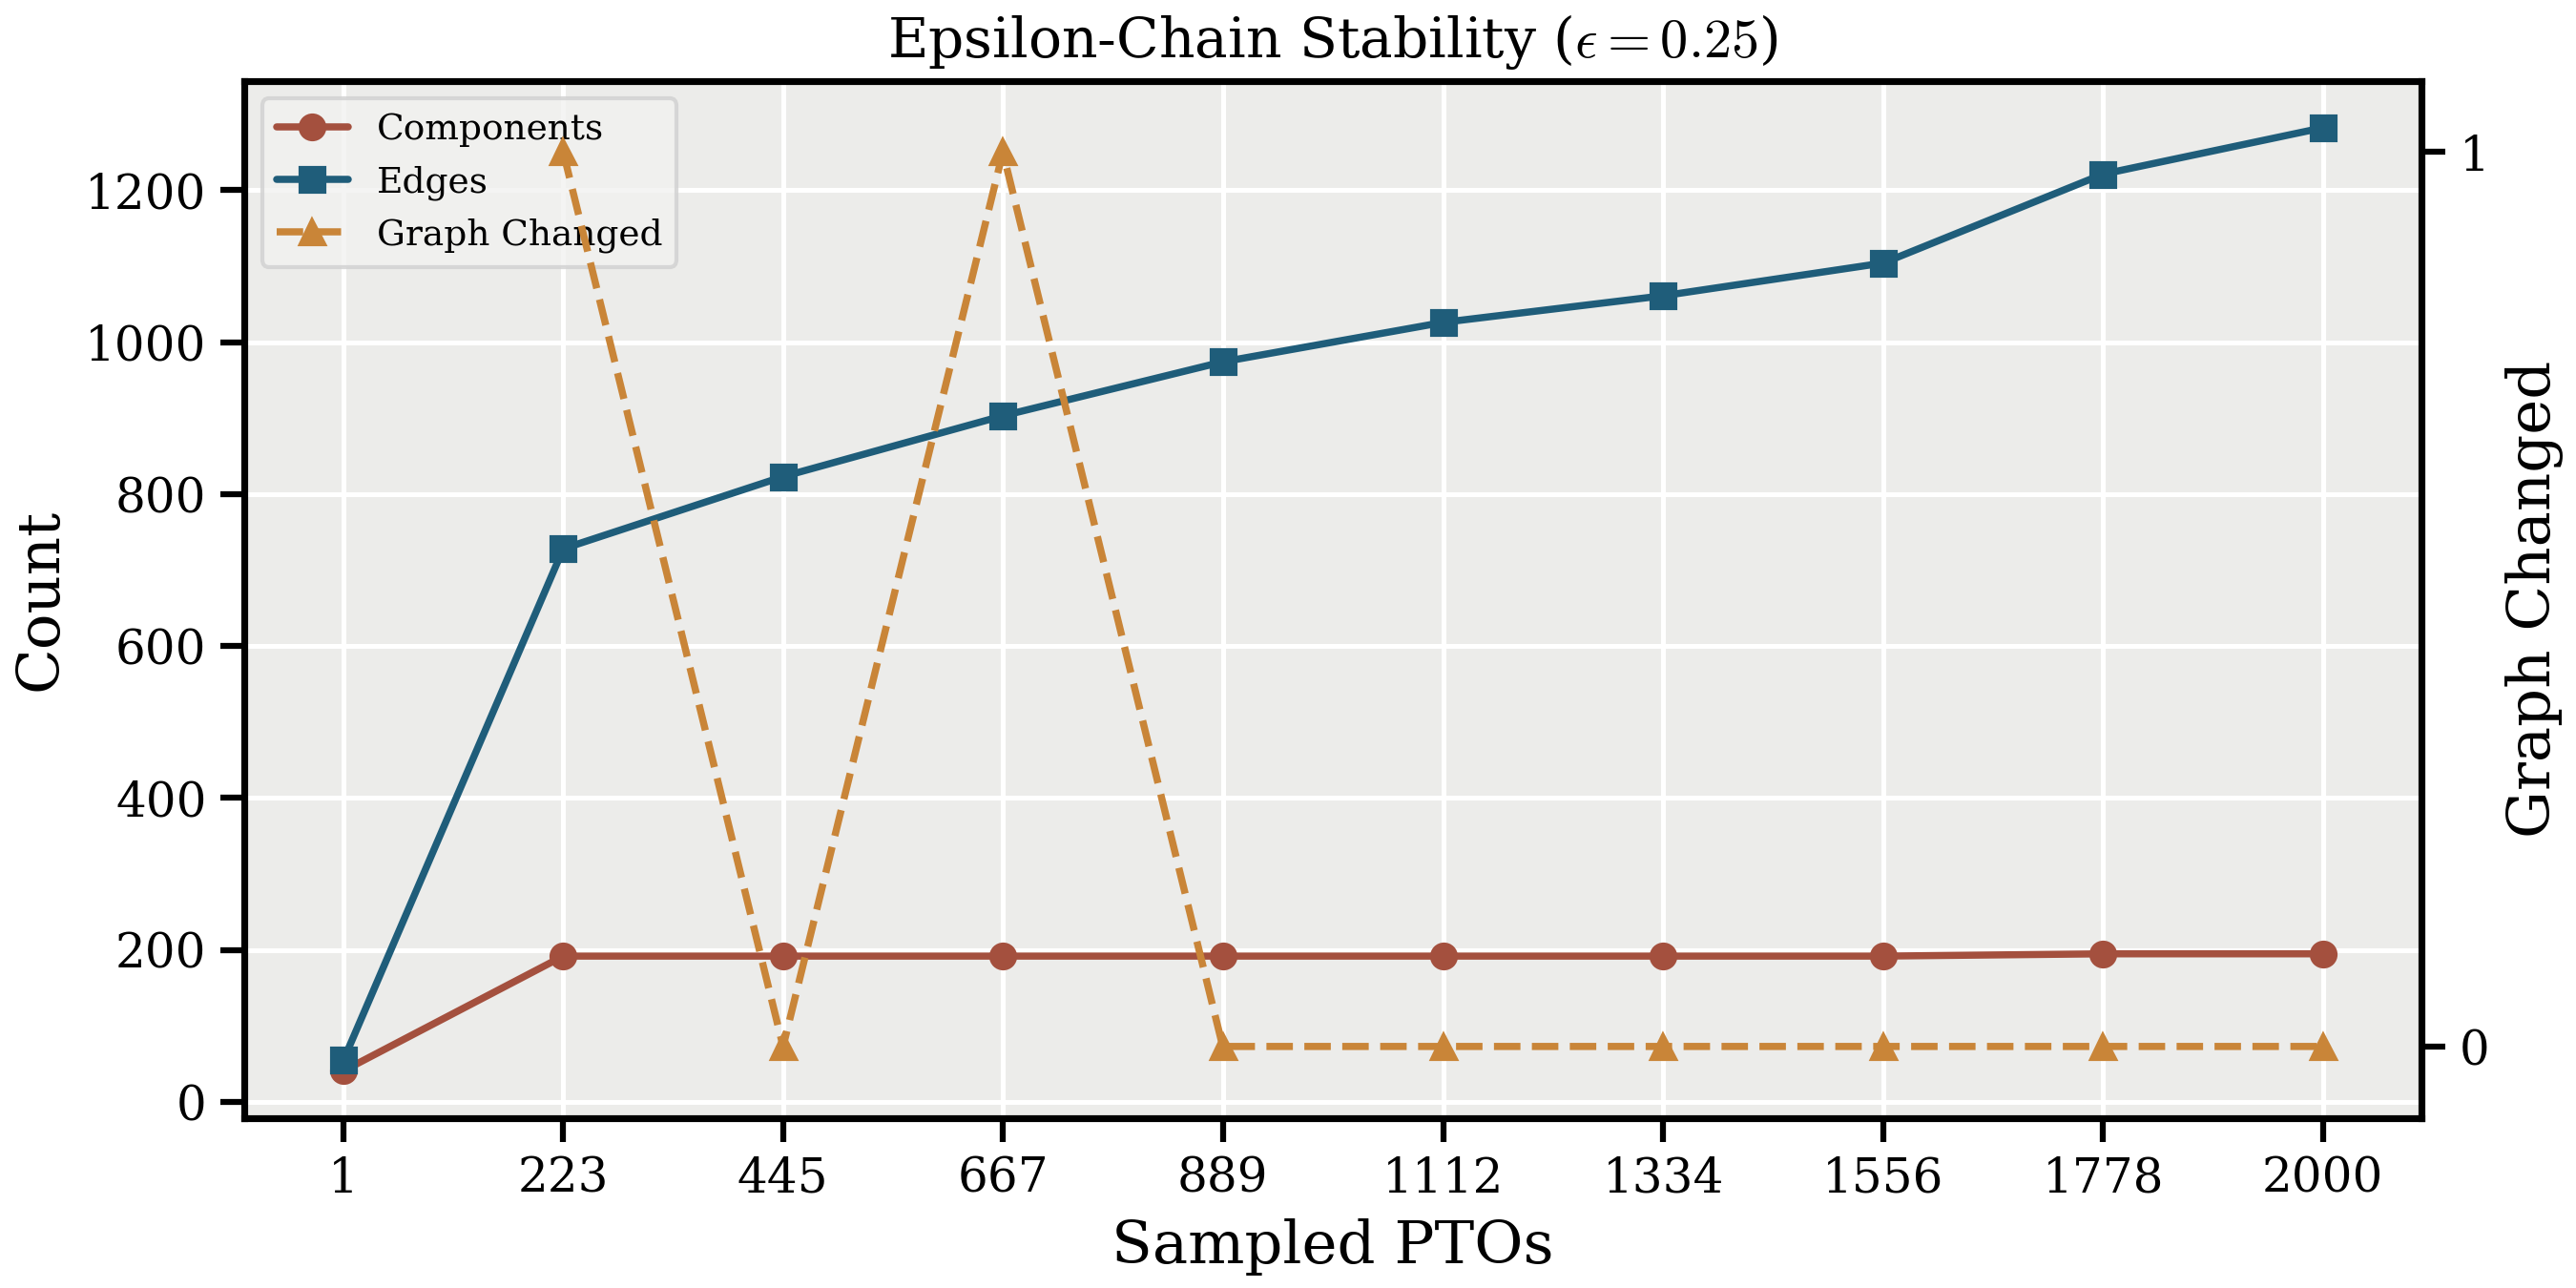

states                                                               182
defined_transitions                                                 1271
proof_scope            Pairs of nonempty decimal operands of arbitrar...
Name: Selected controller, dtype: object

,state,read,write,move,next_state
0,0,0,0,R,0
1,0,1,1,R,0
2,0,2,2,R,0
3,0,3,3,R,0
4,0,4,4,R,0
...,...,...,...,...,...
1266,181,6,6,S,181
1267,181,7,7,S,181
1268,181,8,8,S,181
1269,181,9,9,S,181


controller_sha256                89d1d3c25e6d45298a048046093bfc0bca212d50890bbc...
phases                                                                         207
related_phase_state_pairs                                                      208
local_obligations                                                             1509
checked_nonterminal_entries                                                   1259
defined_entries                                                               1271
unreachable_undefined_entries                                                  913
all_finite_checks_pass                                                        True
seconds                                                                     12.611
Name: Saved verification report, dtype: object

[Case notes](../analyses/metric_extraction/DFST/mult10/warmup_0_steps_4000000/README.md) · [Machine](../analyses/metric_extraction/DFST/mult10/warmup_0_steps_4000000/machines/extracted.json) · [Transition table](../analyses/metric_extraction/DFST/mult10/warmup_0_steps_4000000/machines/extracted.pdf) · [Proof](../analyses/metric_extraction/DFST/mult10/warmup_0_steps_4000000/proof/equivalence_proof.pdf) · [Checker](../analyses/metric_extraction/DFST/mult10/warmup_0_steps_4000000/proof/verify_equivalence.py)

In [2]:
# Set True to run a new extraction; False displays the published cases.
RECOMPUTE = False
SAVE_INTERMEDIATES = False

# Stable indices: 0 = add2, 1 = mult2, 2 = add10, 3 = mult10, 4 = universal.
CASE_INDEX = 3
CASES = analysis_cases(ROOT, "metric_extraction")
case = select_case(CASES, CASE_INDEX)
CASE_CONFIG = yaml.safe_load((ROOT / case["path"] / "config.yaml").read_text())

# Replace this assignment to analyse another complete DEL checkpoint file.
CHECKPOINT_PATH = ROOT / CASE_CONFIG["source_run"] / "final_model_checkpoint.pt"
N_TRAJECTORIES = CASE_CONFIG.get("random_samples", CASE_CONFIG["samples"])
MAX_LENGTH = CASE_CONFIG["max_length"]
TEACHING_SET = CASE_CONFIG.get("teaching_set", False)
EPSILON = CASE_CONFIG["epsilon"]
MAX_STEPS = CASE_CONFIG["max_steps"]

# Exact PTO comparison of the extracted FST.
N_INPUTS = 100
INPUT_LENGTH = 100
# Universal extraction restores the saved program list from config.yaml.
# Edit this list to change the programs sampled for extraction and PTO checks.
# DEFAULT_TP_TASKS is used when the selected case has no saved program list.
UNIVERSAL_TASKS = list(CASE_CONFIG.get("universal_tasks") or DEFAULT_TP_TASKS)
OUTPUT_DIR = Path(os.environ.get("DEL_ANALYSIS_DIR", ROOT / "analysis_outputs" / f"metric_extraction_{datetime.now(timezone.utc):%Y%m%dT%H%M%S%fZ}"))

if not RECOMPUTE:
    print(f"Selected recipe: CASE_INDEX = {CASE_INDEX} ({case['title']}). Displaying published results.")
    show_analysis_case(ROOT, case)


In [3]:
if RECOMPUTE:
    source = Path(CHECKPOINT_PATH).expanduser()
    if not source.is_absolute():
        source = ROOT / source
    source = source.resolve()
    if not source.is_file():
        raise FileNotFoundError(f"Set CHECKPOINT_PATH to an existing checkpoint file: {source}")
    model, expert, config, saved = load_run(source, device="cpu")
    if config["model"]["name"] not in {"DFST", "DFST_Softmax"} or expert.environment not in {"grid", "teleporting"}:
        raise ValueError("This notebook requires a grid or universal DFST/DFST_Softmax checkpoint")
    OUTPUT_DIR = Path(OUTPUT_DIR).expanduser()
    if not OUTPUT_DIR.is_absolute():
        OUTPUT_DIR = ROOT / OUTPUT_DIR
    OUTPUT_DIR = OUTPUT_DIR.resolve()
    print(f"Loaded {source}")
    print(f"New analysis outputs: {OUTPUT_DIR}")
    display(pd.Series({
        "checkpoint_step": saved["step"],
        "model": config["model"]["name"],
        "data_source": config["data"]["source"],
        "training_length": saved["curriculum_length"],
    }, name="Checkpoint settings"))

### Generate Extraction Trajectories

Run the next cell after loading the checkpoint. Expert traces supply initial inputs; the neural controller generates autonomous reads, writes and movements. The workflow appends teaching inputs when requested and saves the sampled inputs in `data/inputs.json`. `SAVE_INTERMEDIATES = True` also saves the trajectories. Nonhalting or nonfinite rollouts raise an error before extraction.


In [4]:
if RECOMPUTE:
    if not math.isfinite(EPSILON) or EPSILON <= 0:
        raise ValueError("EPSILON must be finite and positive")
    if isinstance(MAX_STEPS, bool) or not isinstance(MAX_STEPS, int) or MAX_STEPS < 1:
        raise ValueError("MAX_STEPS must be a positive integer")
    if not isinstance(TEACHING_SET, bool):
        raise ValueError("TEACHING_SET must contain True or False")
    prepare_case(OUTPUT_DIR, SAVE_INTERMEDIATES)
    rng = random.Random()
    rng.setstate(saved["rng"]["sampler"])
    traces = sample_extraction_traces(
        expert, N_TRAJECTORIES, MAX_LENGTH, rng,
        tasks=UNIVERSAL_TASKS if expert.environment == "teleporting" else None,
    )
    base_samples = len(traces)
    teaching_traces = teaching_extraction_traces(expert) if TEACHING_SET else []
    traces.extend(teaching_traces)
    print(f"Extraction inputs: {base_samples:,} random + "
          f"{len(teaching_traces):,} teaching = {len(traces):,}")
    trajectories = closed_loop_trajectories(model, expert, traces, max_steps=MAX_STEPS)
    if SAVE_INTERMEDIATES:
        atomic_save(trajectories, OUTPUT_DIR / "intermediates/trajectories.pt")
    save_case_config(
        OUTPUT_DIR, dict(
            source=str(source),
            source_sha256=hashlib.sha256(source.read_bytes()).hexdigest(),
            source_step=saved["step"],
            config=config,
            epsilon=EPSILON,
            samples=len(traces),
            random_samples=N_TRAJECTORIES,
            base_samples=base_samples,
            teaching_set=TEACHING_SET,
            teaching_samples=len(teaching_traces),
            sampling_recipe=None,
            max_length=MAX_LENGTH,
            max_steps=MAX_STEPS,
            extraction_instances=[trace.metadata for trace in traces],
            universal_tasks=UNIVERSAL_TASKS if expert.environment == "teleporting" else None,
        ),
    )
    print(
        f"Unrolled {len(trajectories)} trajectories: "
        f"{sum(len(t['x_seq']) for t in trajectories)} transitions"
    )


## 2. Extract a Partial FST through Epsilon Chaining

Connect non-halt hidden states within Euclidean distance epsilon and form connected components. If transitions from one component on the same input reach different components, merge the destination components. Repeat until no further merge occurs. Observed outputs must agree; unobserved transitions remain undefined.

Use all sampled trajectories to select a valid epsilon. Start at `EPSILON` and halve the threshold after each output or halt conflict. After 65 unsuccessful attempts, try zero once; an unresolved conflict raises an error. Save the attempts in `data/epsilon_attempts.json`.

At the accepted threshold, start a fresh graph and add one trajectory at a time. Record component counts, edge counts and changes to the rooted labelled graph. The first prefix has no predecessor, so the first change indicator remains undefined. Graph comparison ignores state numbering.

The figure displays at most ten evenly spaced prefixes. The CSV retains measurements for every prefix. `SAVE_INTERMEDIATES = True` also retains each prefix graph. A finite plateau supports inspection of the sampled trajectories; a general stability claim requires additional evidence. The final incremental graph must match the graph extracted from the full sample.


In [5]:
if RECOMPUTE:
    alphabet = tuple(range(expert.input_size))
    effective_epsilon, full_sample_fst, epsilon_attempts = select_valid_epsilon(
        trajectories, alphabet, EPSILON
    )
    atomic_json(epsilon_attempts, OUTPUT_DIR / "data/epsilon_attempts.json")
    print(f"Accepted epsilon: {effective_epsilon:g} (requested {EPSILON:g})")

    rows = []
    for row, extracted in trajectory_stability(trajectories, alphabet, effective_epsilon):
        rows.append(row)
        if SAVE_INTERMEDIATES:
            export_machine(extracted, OUTPUT_DIR / "intermediates/snapshots" / f"epsilon_chain_{row['samples']:06d}")
    assert canonical_graph(extracted) == canonical_graph(full_sample_fst)
    results = pd.DataFrame(rows)
    results.to_csv(OUTPUT_DIR / "data/graph_stability.csv", index=False)
    if SAVE_INTERMEDIATES:
        export_machine(extracted, OUTPUT_DIR / "intermediates/epsilon_chain_partial")
    print(f"Extracted {len(extracted.states)} states and {len(extracted.transitions)} observed transitions")
    display(results.drop(columns="graph_sha256"))


In [6]:
if RECOMPUTE:
    fig, ax, change_ax = plot_graph_stability(results, effective_epsilon)
    for extension in ("png", "pdf"):
        fig.savefig(OUTPUT_DIR / "figures" / f"graph_stability.{extension}", dpi=300)
    display(Image(filename=str(OUTPUT_DIR / "figures/graph_stability.png")))
    plt.close(fig)


## 3. Minimize the Partial FST

Redirect every `S` transition to a dedicated halt state while preserving the written symbol. Halt self-loops define behavior after stopping without adding sampled evidence. Keep unobserved transitions undefined.

Apply Hopcroft partition refinement and number the resulting states with halt last. Retain an explicit halt row even when no observed transition reaches halt. The quotient check verifies the state mapping, and trajectory replay checks every observed output before and after minimization. These checks preserve PTOs through the first `S`; no claim about arbitrary continuations follows.

In [7]:
if RECOMPUTE:
    extracted = with_halt_state(extracted, expert.motion_vocab["S"])
    machine, state_map = hopcroft_minimize(extracted)
    # Retain an explicit halt row even when no observed transition reaches it.
    if not machine.final_states:
        machine = with_halt_state(machine, expert.motion_vocab["S"])
    machine, numbering = number_states(machine)
    state_map = {q: numbering[reduced] for q, reduced in state_map.items()}
    assert verify_quotient(extracted, machine, state_map)
    for trajectory in trajectories:
        for controller in (extracted, machine):
            predicted, covered = controller.predict(trajectory["x_seq"])
            assert covered and predicted == trajectory["sig_seq"]
    if SAVE_INTERMEDIATES:
        export_machine(extracted, OUTPUT_DIR / "intermediates/partial_with_halt")
    atomic_json({str(q): reduced for q, reduced in state_map.items()}, OUTPUT_DIR / "machines/state_map.json")
    print(f"States: {len(extracted.states)} → {len(machine.states)} after Hopcroft minimization")
    print("Exact quotient and trajectory replay checks passed.")


## 4. Visualize the Minimized Partial FST

Rows denote current states; columns denote read symbols. Each defined cell contains `next state | written symbol | motion`. The symbol `λ` denotes blank, and `-` denotes an unobserved transition. State numbering starts at 0 and matches the machine and state-map exports.

The transition table highlights the initial row in green and the halt row in rose. PDF exports embed fonts, readable CSV files support inspection, and SVG panels render inline. Large tables span several panels with repeated headers.

In [8]:
if RECOMPUTE:
    table_paths = save_machine(machine, expert, OUTPUT_DIR / "machines", "extracted")
    for panel in table_paths["panels"]:
        display(SVG(data=panel))
    print("Transition maps:", table_paths["json"], table_paths["csv"], table_paths["pdf"])


## 5. Compare with the Ground-Truth Expert

`N_INPUTS` sets the number of test inputs. `INPUT_LENGTH` sets the exact operand length for grid tasks or binary-word length for universal tasks. Universal checks use `UNIVERSAL_TASKS`. Sampling uses replacement and a copy of the sampler state after extraction.

Compare the minimized controller with expert PTOs until halt, the first differing action or an undefined transition. Matching writes and movements preserve memory and subsequent reads, so a complete match establishes exact PTO agreement for that input. Save inputs and failures in `checks/pto_comparison.json`.

Finite agreement supports counterexample search. A proof for all valid inputs requires an independent argument. Transferring an extracted-controller result to the neural model additionally requires global graph stability and execution coverage.

In [9]:
if RECOMPUTE:
    reference = Transducer(
        {
            (q, expert.vocab[x]): (target, expert.vocab[symbol], expert.motion_vocab[motion])
            for (q, x), (target, symbol, motion) in expert.transitions.items()
        },
        0,
        tuple(range(expert.input_size)),
        frozenset([expert.halt_state]),
    )
    reference, expert_numbering = number_states(reference)
    atomic_json(
        {str(q): reduced for q, reduced in expert_numbering.items()},
        OUTPUT_DIR / "machines/expert_state_map.json",
    )
    expert_table_paths = save_machine(reference, expert, OUTPUT_DIR / "machines", "expert")
    for panel in expert_table_paths["panels"]:
        display(SVG(data=panel))
    print("Expert table:", expert_table_paths["pdf"])


In [10]:
if RECOMPUTE:
    pto_rng = random.Random()
    pto_rng.setstate(rng.getstate())
    report = compare_exact_ptos(
        machine, expert, N_INPUTS, INPUT_LENGTH, pto_rng,
        tasks=UNIVERSAL_TASKS if expert.environment == "teleporting" else None,
    )
    atomic_json(report, OUTPUT_DIR / "checks/pto_comparison.json")
    status = "PASS" if report["all_exact"] else "FAIL"
    print(
        f"{status}: {report['exact_matches']}/{N_INPUTS} exact PTO matches; "
        f"{report['failures']} failures; input length {INPUT_LENGTH}."
    )
    failures = [row for row in report["results"] if not row["exact_match"]]
    if failures:
        display(pd.json_normalize(failures))
    print("Outputs:", OUTPUT_DIR)


## Proof Scope

The proofs concern extracted discrete controllers on the input domains stated in the theorems. Checkers verify finite obligations and supplementary executions; mathematical arguments establish protocol coverage. The notebook performs sampled PTO checks and does not construct these proofs automatically.

- **add2 (index 0):** [proof](../analyses/metric_extraction/DFST/add2/warmup_50000_steps_250000/proof/equivalence_proof.pdf) and [case notes](../analyses/metric_extraction/DFST/add2/warmup_50000_steps_250000/README.md).
- **mult2 (index 1):** [proof](../analyses/metric_extraction/DFST/mult2/warmup_25000_steps_500000/proof/equivalence_proof.pdf) and [case notes](../analyses/metric_extraction/DFST/mult2/warmup_25000_steps_500000/README.md).
- **add10 (index 2):** [proof](../analyses/metric_extraction/DFST/add10/warmup_50000_steps_4000000/proof/equivalence_proof.pdf) and [case notes](../analyses/metric_extraction/DFST/add10/warmup_50000_steps_4000000/README.md).
- **mult10 (index 3):** [proof](../analyses/metric_extraction/DFST/mult10/warmup_0_steps_4000000/proof/equivalence_proof.pdf) and [case notes](../analyses/metric_extraction/DFST/mult10/warmup_0_steps_4000000/README.md). The theorem covers nonempty decimal operands, including leading zeros and zero-valued operands.
- **universal (index 4):** [proof](../analyses/metric_extraction/DFST/universal/data_75_steps_500000/proof/equivalence_proof.pdf) and [case notes](../analyses/metric_extraction/DFST/universal/data_75_steps_500000/README.md). The theorem covers correctly encoded binary Turing machines with nonempty binary inputs. The [empty-input counterexample](../analyses/metric_extraction/DFST/universal/data_75_steps_500000/checks/empty_input_counterexample.json) records the excluded case.


## Output Files

`OUTPUT_DIR` uses the following layout:

| Path | Contents |
|---|---|
| `config.yaml` | Source checkpoint reference, checksum and method settings |
| `machines/extracted.{json,csv,pdf}` | Final extracted controller and readable transition maps |
| `machines/expert.{json,csv,pdf}` | Expert controller and readable transition maps |
| `machines/*state_map.json` | State mappings used by minimization and numbering |
| `figures/` | Main plots in PDF and PNG |
| `data/` | Plot measurements, sampled extraction inputs or annealing probability snapshots |
| `checks/` | Sampled PTO results, counterexamples and supporting checks |
| `checkpoints/annealed_model_checkpoint.pt` | Final annealed weights and continuation state, for annealing only |
| `intermediates/` | Debugging artifacts, written only with `SAVE_INTERMEDIATES = True` |

Published cases additionally contain `README.md` and an independent `proof/`
bundle. The notebooks do not construct equivalence proofs automatically.
Metric extraction retains every row of the stability measurements in either
storage mode. Annealing retains the probability snapshots needed by the viewer
in either mode. SVG panels render inline without permanent SVG or LaTeX exports.
